In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from astropy.cosmology import FlatLambdaCDM
from lenstronomy.Cosmo.lens_cosmo import LensCosmo
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.Util.param_util import phi_q2_ellipticity, shear_polar2cartesian


In [4]:
z_lens = 0.222
z_source = 0.609
cosmo = FlatLambdaCDM(H0=67.77, Om0=0.307)
lens_cosmo = LensCosmo(z_lens=z_lens, z_source=z_source, cosmo=cosmo)

# Use the same position for both objects
perturber_x = -1.111
perturber_y = 1.022

# tNFW parameters --> hold fixed
c_nfw = 10**1.979
r_trunc = 10**(-0.446)   # arcseconds
M200_reference = 10**10.834  # from Ballard et al. (2024)

kwargs_single_band = {
    "pixel_scale": 0.05,
    "exposure_time": 524.0,
    "magnitude_zero_point": 25.94,
    "read_noise": 5.25,
    "ccd_gain": 2.0,
    "sky_brightness": 22.0,
    "num_exposures": 4,
    "seeing": 0.10,
    "psf_type": "GAUSSIAN"}
numpix = 120
supersampling = 3

# EPL + external shear
phi = np.deg2rad(-70.113)
e1, e2 = phi_q2_ellipticity(phi, 0.960)
shear_angle = np.deg2rad(-23.243)
gamma1, gamma2 = shear_polar2cartesian(shear_angle, 0.107)

kwargs_epl = {
    "theta_E": 1.397,
    "gamma": 2.123,
    "e1": e1,
    "e2": e2,
    "center_x": 0.031,
    "center_y": 0.047,}
kwargs_shear = {"gamma1": gamma1, "gamma2": gamma2}
kwargs_main_lens = [kwargs_epl, kwargs_shear]

kwargs_source_mag = [{
    "magnitude": 22.76,
    "R_sersic": 0.18,
    "n_sersic": 1,
    "e1": 0.15,
    "e2": 0.05,
    "center_x": 0.08,
    "center_y": -0.03}]


In [7]:
# Function to calculate total mass
def tnfw_total_mass(M200):
    rs_angle, _ = lens_cosmo.nfw_physical2angle(M=M200, c=c_nfw)
    tau = r_trunc / rs_angle
    f_c = np.log(1 + c_nfw) - c_nfw / (1 + c_nfw)

    def integrand(x):
        nfw_term = x / (1 + x)**2
        truncation_term = tau**2 / (x**2 + tau**2)
        return nfw_term * truncation_term

    integral, integration_error = quad(integrand, 0, np.inf)
    return M200 * integral / f_c

M_sub_reference = tnfw_total_mass(M200_reference)
print(f"Reference untruncated M200: {M200_reference:.4e} M_sun")
print(f"Reference truncated total mass: {M_sub_reference:.4e} M_sun")


Reference untruncated M200: 6.8234e+10 M_sun
Reference truncated total mass: 8.3623e+09 M_sun


In [9]:
# Create image model for each perturbation
kwargs_model_bh = {
    "lens_model_list": ["EPL", "SHEAR", "POINT_MASS"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}
kwargs_model_nfw = {
    "lens_model_list": ["EPL", "SHEAR", "TNFW"],
    "source_light_model_list": ["SERSIC_ELLIPSE"]}

sim_bh = SimAPI(numpix=numpix,
                kwargs_single_band=kwargs_single_band,
                kwargs_model=kwargs_model_bh)
sim_nfw = SimAPI(numpix=numpix,
                 kwargs_single_band=kwargs_single_band,
                 kwargs_model=kwargs_model_nfw)

model_bh = sim_bh.image_model_class(kwargs_numerics={"supersampling_factor": supersampling})
model_nfw = sim_nfw.image_model_class(kwargs_numerics={"supersampling_factor": supersampling})

_, kwargs_source, _ = sim_nfw.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)

# Unperturbed baselines 
kwargs_bh_off = {
    "theta_E": 0.0,      # removes the BH
    "center_x": perturber_x,
    "center_y": perturber_y}
kwargs_nfw_off = {
    "Rs": 1.0,       
    "alpha_Rs": 0.0,    # removes the halo
    "r_trunc": r_trunc,
    "center_x": perturber_x,
    "center_y": perturber_y}

baseline_bh = model_bh.image(
    kwargs_lens=kwargs_main_lens + [kwargs_bh_off],
    kwargs_source=kwargs_source)
baseline_nfw = model_nfw.image(
    kwargs_lens=kwargs_main_lens + [kwargs_nfw_off],
    kwargs_source=kwargs_source)

In [11]:
# Create list of masses
M200_values = np.logspace(8.5, 13, 20)  # solar masses

masses_total = []
rms_bh = []
rms_nfw = []

rms_bh_nfw = []
bh_nfw_residuals = []
saved_cases = {}

inspect_targets = [1e11, 3e11, 1e12]

point_mass_at_1arcsec = lens_cosmo.mass_in_theta_E(1.0)

for M200_trial in M200_values:
    M_sub = tnfw_total_mass(M200_trial)
    rs_angle, alpha_Rs = lens_cosmo.nfw_physical2angle(M=M200_trial, c=c_nfw)

    kwargs_tnfw_trial = {
        "Rs": rs_angle,
        "alpha_Rs": alpha_Rs,
        "r_trunc": r_trunc,
        "center_x": perturber_x,
        "center_y": perturber_y}

    image_nfw = model_nfw.image(
        kwargs_lens=kwargs_main_lens + [kwargs_tnfw_trial],
        kwargs_source=kwargs_source)

    M_bh = M_sub
    theta_E_bh = np.sqrt(M_bh / point_mass_at_1arcsec)
    kwargs_bh_trial = {
        "theta_E": theta_E_bh,
        "center_x": perturber_x,
        "center_y": perturber_y}

    image_bh = model_bh.image(
        kwargs_lens=kwargs_main_lens + [kwargs_bh_trial],
        kwargs_source=kwargs_source)

    # To generate image of a specific trial later on if need to
    saved_cases[M_sub] = {
    "baseline_bh": baseline_bh.copy(),
    "baseline_nfw": baseline_nfw.copy(),
    "image_bh": image_bh.copy(),
    "image_nfw": image_nfw.copy(),
    "residual_bh": (image_bh - baseline_bh).copy(),
    "residual_nfw": (image_nfw - baseline_nfw).copy(),
    "difference_bh_nfw": (image_bh - image_nfw).copy(),
    "rms_bh": np.sqrt(np.mean((image_bh - baseline_bh)**2)),
    "rms_nfw": np.sqrt(np.mean((image_nfw - baseline_nfw)**2)),
    "rms_bh_nfw": np.sqrt(np.mean((image_bh - image_nfw)**2)),
    "M200": M200_trial}
    
    image_difference_bh_nfw = image_bh - image_nfw

    rms_difference_bh_nfw = np.sqrt(np.mean(image_difference_bh_nfw**2))

    rms_bh_nfw.append(rms_difference_bh_nfw)
    bh_nfw_residuals.append(image_difference_bh_nfw)

    residual_bh = image_bh - baseline_bh
    residual_nfw = image_nfw - baseline_nfw

    masses_total.append(M_sub)
    rms_bh.append(np.sqrt(np.mean(residual_bh**2)))
    rms_nfw.append(np.sqrt(np.mean(residual_nfw**2)))

    print(f"M200={M200_trial:.3e}  | total mass={M_sub:.3e} | "
          f"BH RMS={rms_bh[-1]:.5g} | tNFW RMS={rms_nfw[-1]:.5g}")


M200=3.162e+08  | total mass=1.333e+08 | BH RMS=0.00045086 | tNFW RMS=0.00033338
M200=5.456e+08  | total mass=2.088e+08 | BH RMS=0.00070356 | tNFW RMS=0.00051347
M200=9.412e+08  | total mass=3.252e+08 | BH RMS=0.0010942 | tNFW RMS=0.0007857
M200=1.624e+09  | total mass=5.035e+08 | BH RMS=0.001695 | tNFW RMS=0.0011941
M200=2.801e+09  | total mass=7.745e+08 | BH RMS=0.002606 | tNFW RMS=0.0018018
M200=4.833e+09  | total mass=1.184e+09 | BH RMS=0.0039558 | tNFW RMS=0.0026987
M200=8.338e+09  | total mass=1.796e+09 | BH RMS=0.0058417 | tNFW RMS=0.0040107
M200=1.438e+10  | total mass=2.706e+09 | BH RMS=0.008472 | tNFW RMS=0.0059119
M200=2.482e+10  | total mass=4.047e+09 | BH RMS=0.012016 | tNFW RMS=0.0086373
M200=4.281e+10  | total mass=6.005e+09 | BH RMS=0.016631 | tNFW RMS=0.012493
M200=7.386e+10  | total mass=8.841e+09 | BH RMS=0.022175 | tNFW RMS=0.017817
M200=1.274e+11  | total mass=1.291e+10 | BH RMS=0.026774 | tNFW RMS=0.024602
M200=2.198e+11  | total mass=1.870e+10 | BH RMS=0.02969 | 

In [13]:
import pandas as pd

df = pd.DataFrame({
    "mass": masses_total,
    "rms_bh_nfw": rms_bh_nfw})

df.to_csv("rms_120.csv", index=False)



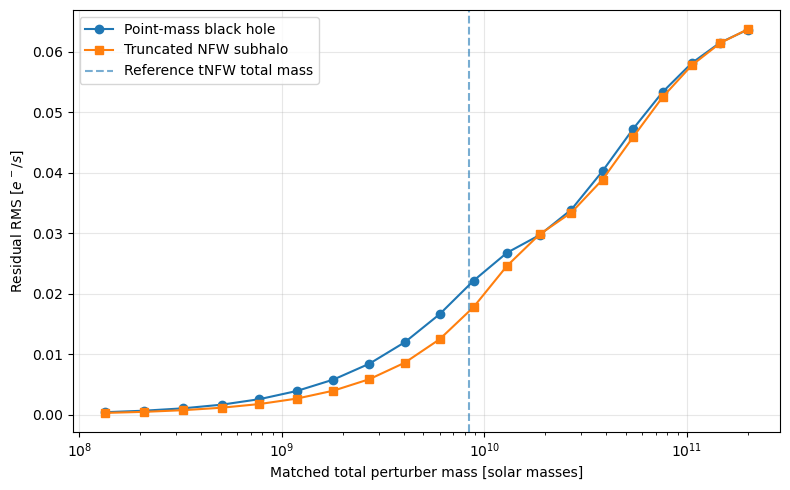

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(masses_total, rms_bh, marker="o", label="Point-mass black hole")
ax.plot(masses_total, rms_nfw, marker="s", label="Truncated NFW subhalo")
ax.axvline(M_sub_reference, linestyle="--", alpha=0.6,
           label="Reference tNFW total mass")

ax.set_xscale("log")
ax.set_xlabel("Matched total perturber mass [solar masses]")
ax.set_ylabel(r"Residual RMS [$e^-/s$]")
# ax.set_title("Lensing perturbation strength vs. total mass")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("rms_vs_matched_perturber_mass.png", dpi=300, bbox_inches="tight")
plt.show()


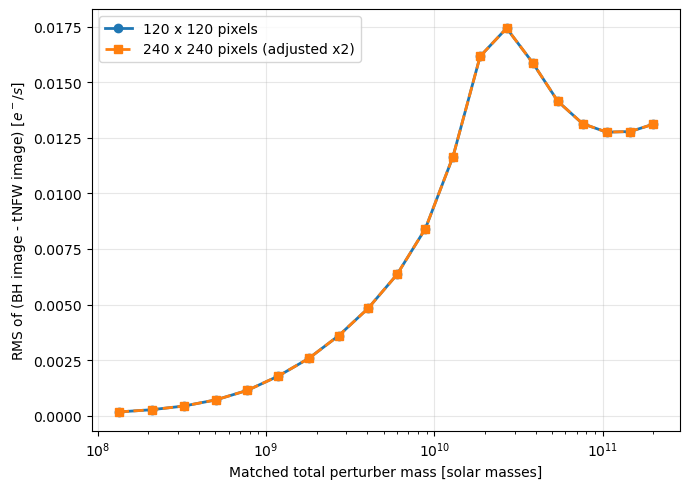

In [23]:

import pandas as pd
import matplotlib.pyplot as plt

small = pd.read_csv("rms_120.csv")
large = pd.read_csv("rms_240.csv")

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    small["mass"],
    small["rms_bh_nfw"],
    marker="o",
    linewidth=2,
    label="120 x 120 pixels")

ax.plot(
    large["mass"],
    large["rms_bh_nfw"] * 2,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="240 x 240 pixels (adjusted x2)")

ax.set_xscale("log")
ax.set_xlabel("Matched total perturber mass [solar masses]")
ax.set_ylabel("RMS of (BH image - tNFW image) [$e^-/s$]")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("rms_between_perturbers_vs_matched_perturber_mass.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [107]:
print(saved_cases.keys())

for mass in saved_cases:
    print(f"{mass:.3e}")

dict_keys([133329449.87442672, 208821153.34526506, 325215025.8989649, 503464470.15702546, 774506487.5234686, 1183583858.379449, 1796209042.1676588, 2706286810.6511374, 4047034738.883146, 6005481067.167161, 8841481018.351662, 12912380772.026878, 18704681869.204987, 26874331191.458984, 38297601082.19434, 54134953777.769196, 75910831605.15726, 105613010658.65053, 145816035590.55225, 199834355230.72525])
1.333e+08
2.088e+08
3.252e+08
5.035e+08
7.745e+08
1.184e+09
1.796e+09
2.706e+09
4.047e+09
6.005e+09
8.841e+09
1.291e+10
1.870e+10
2.687e+10
3.830e+10
5.413e+10
7.591e+10
1.056e+11
1.458e+11
1.998e+11


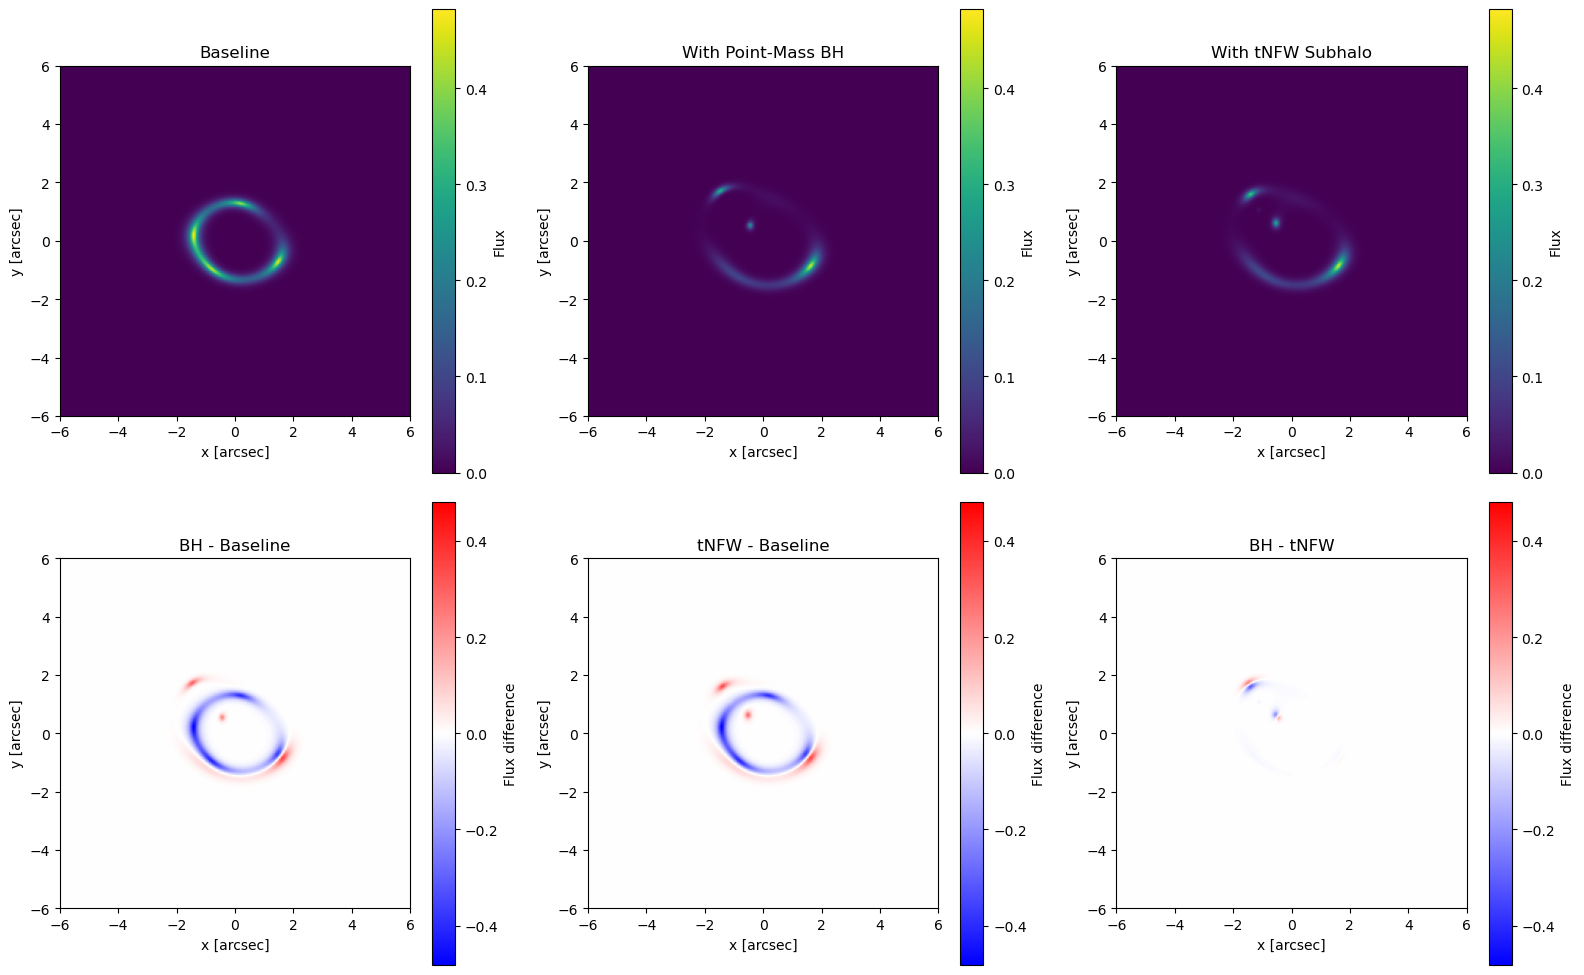

In [109]:
pixel_scale = kwargs_single_band["pixel_scale"]
image_size = numpix * pixel_scale

extent = [
    -image_size / 2,
     image_size / 2,
    -image_size / 2,
     image_size / 2]

target = 105613010658.65053 

case = saved_cases[target]

baseline = case["baseline_bh"]   # should be essentially same as baseline_nfw
image_bh = case["image_bh"]
image_nfw = case["image_nfw"]
residual_bh = case["residual_bh"]
residual_nfw = case["residual_nfw"]
difference_bh_nfw = case["difference_bh_nfw"]

flux_max = max(baseline.max(), image_bh.max(), image_nfw.max())
resid_max = max(
    np.max(np.abs(residual_bh)),
    np.max(np.abs(residual_nfw)),
    np.max(np.abs(difference_bh_nfw)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Baseline
im0 = axes[0, 0].imshow(
    baseline, origin="lower", extent=extent,
    cmap="viridis", vmin=0, vmax=flux_max)
axes[0, 0].set_title("Baseline")
axes[0, 0].set_xlabel("x [arcsec]")
axes[0, 0].set_ylabel("y [arcsec]")
fig.colorbar(im0, ax=axes[0, 0], label="Flux")

# BH image
im1 = axes[0, 1].imshow(
    image_bh, origin="lower", extent=extent,
    cmap="viridis", vmin=0, vmax=flux_max)
axes[0, 1].set_title("With Point-Mass BH")
axes[0, 1].set_xlabel("x [arcsec]")
axes[0, 1].set_ylabel("y [arcsec]")
fig.colorbar(im1, ax=axes[0, 1], label="Flux")

# NFW image
im2 = axes[0, 2].imshow(
    image_nfw, origin="lower", extent=extent,
    cmap="viridis", vmin=0, vmax=flux_max)
axes[0, 2].set_title("With tNFW Subhalo")
axes[0, 2].set_xlabel("x [arcsec]")
axes[0, 2].set_ylabel("y [arcsec]")
fig.colorbar(im2, ax=axes[0, 2], label="Flux")

# BH residual
im3 = axes[1, 0].imshow(
    residual_bh, origin="lower", extent=extent,
    cmap="bwr", vmin=-resid_max, vmax=resid_max)
axes[1, 0].set_title("BH - Baseline")
axes[1, 0].set_xlabel("x [arcsec]")
axes[1, 0].set_ylabel("y [arcsec]")
fig.colorbar(im3, ax=axes[1, 0], label="Flux difference")

# NFW residual
im4 = axes[1, 1].imshow(
    residual_nfw, origin="lower", extent=extent,
    cmap="bwr", vmin=-resid_max, vmax=resid_max)
axes[1, 1].set_title("tNFW - Baseline")
axes[1, 1].set_xlabel("x [arcsec]")
axes[1, 1].set_ylabel("y [arcsec]")
fig.colorbar(im4, ax=axes[1, 1], label="Flux difference")

# BH - NFW difference
im5 = axes[1, 2].imshow(
    difference_bh_nfw, origin="lower", extent=extent,
    cmap="bwr", vmin=-resid_max, vmax=resid_max)
axes[1, 2].set_title("BH - tNFW")
axes[1, 2].set_xlabel("x [arcsec]")
axes[1, 2].set_ylabel("y [arcsec]")
fig.colorbar(im5, ax=axes[1, 2], label="Flux difference")

plt.tight_layout()
plt.show()

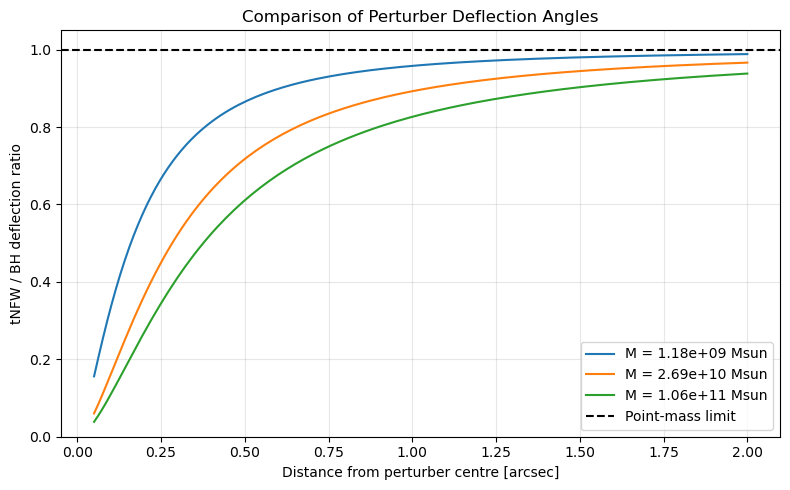

In [15]:
from lenstronomy.LensModel.lens_model import LensModel

lens_bh = LensModel(lens_model_list=["POINT_MASS"])
lens_nfw = LensModel(lens_model_list=["TNFW"])

# Masses want to inspect (total mass)
mass_choices = [1e9, 3e10, 1e11]

# Distances from perturber centre 
b_values = np.linspace(0.05, 2.0, 150)

# Positions at which to calculate deflection
x = perturber_x + b_values
y = np.full_like(b_values, perturber_y)

fig, ax = plt.subplots(figsize=(8, 5))

total_masses = []

for M200_trial in M200_values:
    total_masses.append(tnfw_total_mass(M200_trial))


for target_mass in mass_choices:

    # Find the simulated mass closest to target
    index = np.argmin(np.abs(np.log10(total_masses) - np.log10(target_mass)))

    M200_trial = M200_values[index]
    M_sub = total_masses[index]

    Rs, alpha_Rs = lens_cosmo.nfw_physical2angle(M=M200_trial, c=c_nfw)

    kwargs_nfw = {
        "Rs": Rs,
        "alpha_Rs": alpha_Rs,
        "r_trunc": r_trunc,
        "center_x": perturber_x,
        "center_y": perturber_y}

    # BH with same total mass
    theta_E_bh = np.sqrt(M_sub / lens_cosmo.mass_in_theta_E(1.0))

    kwargs_bh = {
        "theta_E": theta_E_bh,
        "center_x": perturber_x,
        "center_y": perturber_y}

    # Calculate BH deflection components
    alpha_bh_x, alpha_bh_y = lens_bh.alpha(x, y, [kwargs_bh])

    # Calculate NFW deflection components
    alpha_nfw_x, alpha_nfw_y = lens_nfw.alpha(x, y, [kwargs_nfw])

    alpha_bh = np.sqrt(alpha_bh_x**2 + alpha_bh_y**2)
    alpha_nfw = np.sqrt(alpha_nfw_x**2 + alpha_nfw_y**2)

    ratio = alpha_nfw / alpha_bh

    ax.plot(b_values, ratio, label=f"M = {M_sub:.2e} Msun")

# Point-mass 
ax.axhline(1.0, color="black", linestyle="--", label="Point-mass limit")

ax.set_xlabel("Distance from perturber centre [arcsec]")
ax.set_ylabel("tNFW / BH deflection ratio")
ax.set_title("Comparison of Perturber Deflection Angles")

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.savefig("deflection_angle_comparison.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()